# EUR/USD: how well can we forecast tomorrow's volatility?

Volatility is how much a price moves. It matters for anyone who carries risk:
position sizes, risk limits and option prices all depend on how much the price
is expected to move tomorrow. Unlike the direction of the next move, volatility
is genuinely forecastable, because calm and turbulent periods last.

This notebook asks one question for the euro–dollar exchange rate: **which model
best forecasts the next day's volatility?** It

1. builds a daily volatility measure, *realized variance*, from tick data;
2. looks at how that series behaves;
3. forecasts it out of sample with five models, refitted every day;
4. scores the forecasts with QLIKE and tests the differences with the
   Diebold–Mariano test;
5. checks that the conclusion does not hinge on one setting or a few months.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rvol import experiment
from rvol.data.volatility import build_daily_dataset
from rvol.evaluation import hac_sensitivity

ASSET = "EURUSD"
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TICKS = sorted((ROOT / "data" / "ticks" / ASSET).glob("*.parquet"))
CACHE = ROOT / "data" / "derived" / f"{ASSET}_daily_rv_5min.parquet"

MIN_TRAIN_SESSIONS = 252  # about one year of history before the first forecast
CALIBRATION_START = date(2024, 10, 1)  # Oct-Dec 2024 forecasts only calibrate smearing
EVALUATION_START = date(2025, 1, 1)
FORECAST_END = date(2026, 9, 30)
SESSIONS_PER_YEAR = 260  # five FX sessions a week

MODELS = ["HAR", "AR1", "EWMA", "naive", "historical_mean"]
COLORS = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"], strict=True))
ACTUAL = "#8a8984"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#8a8984",
        "axes.labelcolor": "#52514e",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "font.size": 10,
        "legend.frameon": False,
        "lines.linewidth": 1.4,
    }
)


def annualized_vol(variance):
    # Daily variance -> annualized volatility in percent, the unit traders quote.
    return 100 * np.sqrt(SESSIONS_PER_YEAR * np.asarray(variance, dtype="float64"))

## 1. From ticks to daily realized variance

**Ticks.** The raw data are Dukascopy quotes: every time the best bid or ask
price for EUR/USD changes, a new row appears, often several times a second. We
use the *mid price*, the average of bid and ask.

**Sessions.** Currencies trade around the clock from Sunday evening to Friday
evening. By market convention a trading day, or *session*, runs from 17:00 New
York time to 17:00 the next day, so each session is one row of daily data.
Sessions shorter than 12 hours (holidays, the Sunday open) are dropped.

**Realized variance.** Within a session we take the last mid price in every
5-minute interval, $P_0, P_1, \dots, P_n$ with $n \approx 288$, and sum the
squared log returns:

$$
\mathrm{RV}_t = \sum_{i=1}^{n} \left(\log P_i - \log P_{i-1}\right)^2 .
$$

As the grid gets finer, RV converges to the day's integrated variance, the true
amount of movement. Very fine grids pick up bid–ask noise instead, and five
minutes is the standard compromise. Building the series from ~1 GB of ticks
takes about a minute and a half, so the result is cached; delete the cache
file to rebuild it after changing the RV code.

In [2]:
newest_ticks = max(path.stat().st_mtime for path in TICKS)
if CACHE.exists() and CACHE.stat().st_mtime > newest_ticks:
    daily = pd.read_parquet(CACHE)
else:
    daily = build_daily_dataset(TICKS)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    daily.to_parquet(CACHE, index=False)
daily.tail()

,date,rv_5min,log_rv,observation_count
968,2026-09-25,0.000008,-11.701473,288
969,2026-09-28,0.000012,-11.337759,288
970,2026-09-29,0.000011,-11.395401,288
971,2026-09-30,0.000013,-11.226630,288
972,2026-10-01,0.000027,-10.538294,288


Before modelling, check the series: one row per session, no long gaps, and
roughly 288 five-minute prices in every session.

In [3]:
pd.Series(
    {
        "sessions": len(daily),
        "first session": daily["date"].min().date(),
        "last session": daily["date"].max().date(),
        "duplicate dates": int(daily["date"].duplicated().sum()),
        "longest gap between sessions (days)": int(daily["date"].diff().dt.days.max()),
        "sessions with all 288 five-minute prices": int((daily["observation_count"] == 288).sum()),
        "fewest five-minute prices in a session": int(daily["observation_count"].min()),
    },
    name="value",
).to_frame()

,value
sessions,973
first session,2023-01-02
last session,2026-10-01
duplicate dates,0
longest gap between sessions (days),4
sessions with all 288 five-minute prices,946
fewest five-minute prices in a session,278


Almost every session has all 288 five-minute prices, and the rest miss at most
ten, so each RV covers nearly the whole session. The longest gap is four days,
a holiday weekend.

## 2. What realized variance looks like

RV is a daily variance, a small number like $2\times10^{-5}$. For reading charts
it is easier to convert it to **annualized volatility**,
$100\sqrt{260\,\mathrm{RV}_t}$ percent, the unit in which traders quote
volatility: "EUR/USD vol is 7%" means a typical yearly move of about 7%.

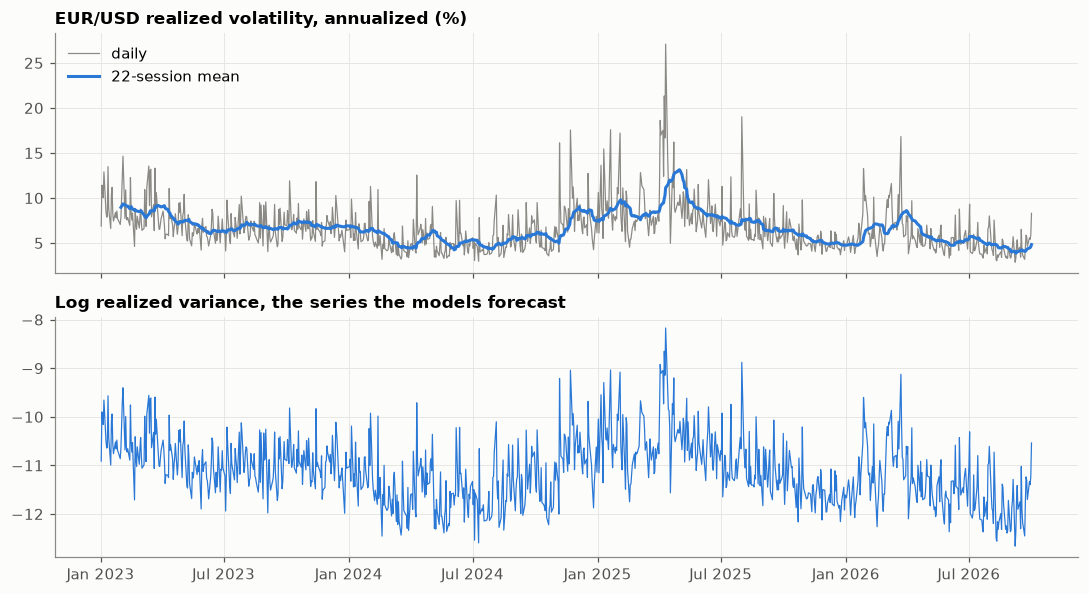

In [4]:
dates = daily["date"]
vol = annualized_vol(daily["rv_5min"])

fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(dates, vol, color=ACTUAL, linewidth=0.8, label="daily")
axes[0].plot(
    dates,
    pd.Series(vol).rolling(22).mean(),
    color=COLORS["HAR"],
    linewidth=2,
    label="22-session mean",
)
axes[0].set_title("EUR/USD realized volatility, annualized (%)")
axes[0].legend(loc="upper left")
axes[1].plot(dates, daily["log_rv"], color=COLORS["HAR"], linewidth=0.8)
axes[1].set_title("Log realized variance, the series the models forecast")
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()

Two features stand out. Volatility **clusters**: quiet and turbulent stretches
last for weeks. And it has **spikes**: single days several times the usual
level. The spikes are why the models work with $\log \mathrm{RV}$: RV itself is
strongly right-skewed, while its logarithm is close to symmetric, so a few
extreme days do not dominate a least-squares fit.

,skewness
RV,5.23
log RV,0.47


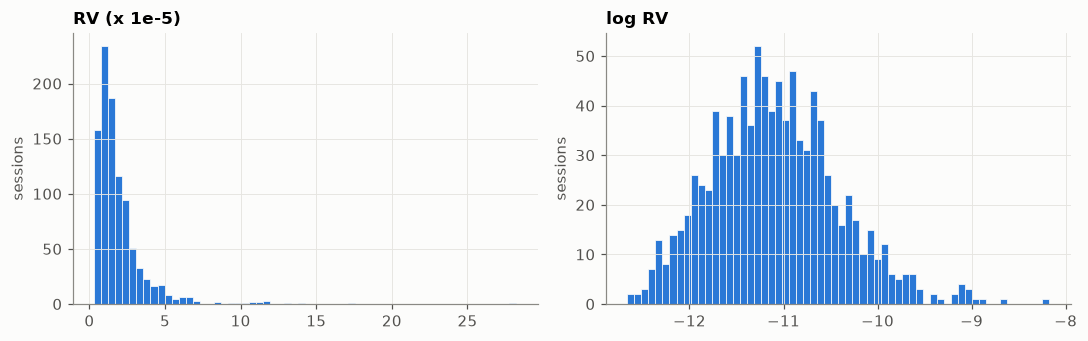

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(
    daily["rv_5min"] * 1e5, bins=60, color=COLORS["HAR"], edgecolor="#fcfcfb", linewidth=0.5
)
axes[0].set_title("RV (x 1e-5)")
axes[1].hist(daily["log_rv"], bins=60, color=COLORS["HAR"], edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set_title("log RV")
for ax in axes:
    ax.set_ylabel("sessions")
fig.tight_layout()

pd.DataFrame(
    {"skewness": [daily["rv_5min"].skew(), daily["log_rv"].skew()]}, index=["RV", "log RV"]
).round(2)

**Persistence.** The autocorrelation of log RV measures how much today's
volatility tells us about volatility $k$ sessions later.

1     0.59
5     0.48
22    0.32
60    0.22
Name: autocorrelation, dtype: float64

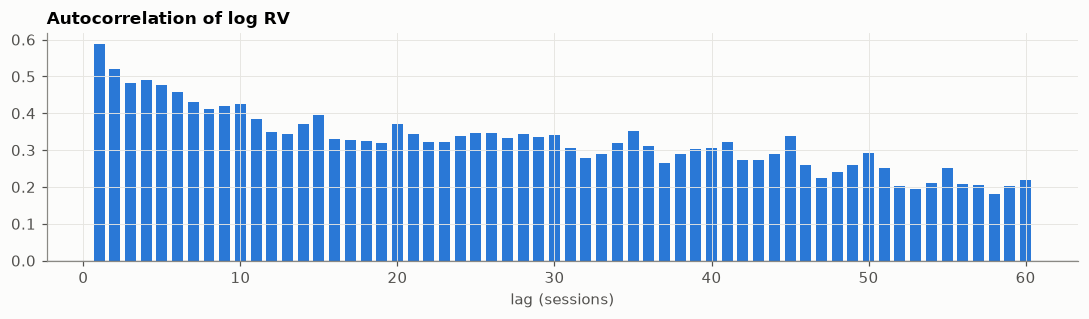

In [6]:
log_rv = daily["log_rv"].to_numpy()
lags = np.arange(1, 61)
autocorrelation = [np.corrcoef(log_rv[:-k], log_rv[k:])[0, 1] for k in lags]

fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(lags, autocorrelation, width=0.7, color=COLORS["HAR"])
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_title("Autocorrelation of log RV")
ax.set_xlabel("lag (sessions)")
fig.tight_layout()
pd.Series(autocorrelation, index=lags).loc[[1, 5, 22, 60]].rename("autocorrelation").round(2)

The autocorrelation decays slowly: volatility a month ago still carries
information about tomorrow. A model that only looks at today (AR(1)) or that
forgets at a fixed exponential rate (EWMA) will struggle to capture this; that
is the motivation for HAR in the next section.

## 3. Models and walk-forward forecasts

Every model predicts $y_{t+1} = \log \mathrm{RV}_{t+1}$ from information
available at the end of session $t$. The five models are special cases of two
forecasting rules.

**Exponential smoothing** with fixed weights forecasts $s_t$, where
$s_k = \lambda\,s_{k-1} + (1-\lambda)\,y_k$ and $\lambda \in [0, 1)$ is chosen in
advance, not estimated.

**Linear regression** forecasts $a + x_t^\top b$, with $a$ and $b$ estimated by
least squares on the past.

| rule | model | forecast of $y_{t+1}$ |
|---|---|---|
| smoothing | naive | $y_t$, the case $\lambda = 0$: tomorrow looks like today |
| smoothing | EWMA | $s_t$ with $\lambda = 0.94$ (the RiskMetrics value): weight $0.06$ on today |
| regression | historical mean | $a$: no regressors, so $a$ is the mean of past $y$ |
| regression | AR(1) | $a + b\,y_t$ |
| regression | HAR | $a + b_d\,y_t + b_w\,\bar y^{(5)}_t + b_m\,\bar y^{(22)}_t$ |

$\bar y^{(5)}_t$ and $\bar y^{(22)}_t$ are the means of $y$ over the last 5 and
22 sessions, roughly a week and a month. HAR (Corsi, 2009) is a regression on
volatility over three horizons. It is a simple way to capture the slow decay
seen above.

**Walk-forward.** Each session, every model is refitted on all outcomes
observed so far (at least 252 sessions) and forecasts the next session only.
No forecast ever uses data from its own future. Forecasts start in October
2024; the first three months only calibrate the correction in section 4, and
the evaluation runs from January 2025.

In [7]:
prepared = experiment.prepare(daily)
forecasts = experiment.forecast(
    prepared,
    experiment.benchmark_models(),
    start=CALIBRATION_START,
    end=FORECAST_END,
    min_train_size=MIN_TRAIN_SESSIONS,
    asset=ASSET,
)
forecasts.groupby("model").size().rename("forecasts").to_frame()

,forecasts
model,
AR1,518
EWMA,518
HAR,518
historical_mean,518
naive,518


What HAR learns: the coefficients fitted on everything before the evaluation
period.

In [8]:
history = prepared.loc[prepared["target_date"] < pd.Timestamp(EVALUATION_START)]
har = next(model for model in experiment.benchmark_models() if model.name == "HAR")
fitted = har.rule.fit(history[list(har.regressors)].to_numpy(), history["target"].to_numpy())
coefficients = pd.Series(
    [fitted.intercept, *fitted.coefficients],
    index=["intercept", "daily b_d", "weekly b_w", "monthly b_m"],
    name="HAR coefficient",
)
coefficients.round(3).to_frame()

,HAR coefficient
intercept,-1.692
daily b_d,0.125
weekly b_w,0.468
monthly b_m,0.255


The weekly and monthly averages carry most of the weight (about 0.47 and 0.26)
and today's value only about 0.13: tomorrow's volatility depends more on the
recent level than on today's single, noisy measurement. The three slopes sum to
less than one, so forecasts are pulled back towards a long-run level.

## 4. From log forecasts back to variance

The models forecast $\log \mathrm{RV}$, but the quantity we care about is RV
itself. Simply exponentiating is biased: if $y_{t+1} = \hat y_{t+1} + \varepsilon$
with mean-zero errors, then

$$
\mathbb{E}[\mathrm{RV}_{t+1}] = e^{\hat y_{t+1}}\,\mathbb{E}[e^{\varepsilon}] > e^{\hat y_{t+1}}
$$

by Jensen's inequality, so $e^{\hat y}$ is too low on average. The **Duan
smearing** correction multiplies each forecast by the average of $e^{\varepsilon}$
over the model's past errors, using only errors already observed when the
forecast is made. For normal errors the factor would be
$e^{\sigma^2/2}$.

In [9]:
comparison = experiment.compare(forecasts, evaluation_start=EVALUATION_START)
variance = comparison.forecasts

variance.groupby("model")["smearing_factor"].agg(["mean", "min", "max"]).loc[MODELS].round(3)

,mean,min,max
model,,,
HAR,1.256,1.169,1.401
AR1,1.404,1.205,1.623
EWMA,1.287,1.186,1.507
naive,1.302,1.230,1.511
historical_mean,1.730,1.342,2.225


HAR's factor averages about 1.26: without the correction its variance forecasts
would be roughly 20% too low ($1 - 1/1.26$). The factor is largest for the
historical mean, whose log errors are the largest.

Forecasts against what happened, for the last six months of the sample, on the
annualized-volatility scale:

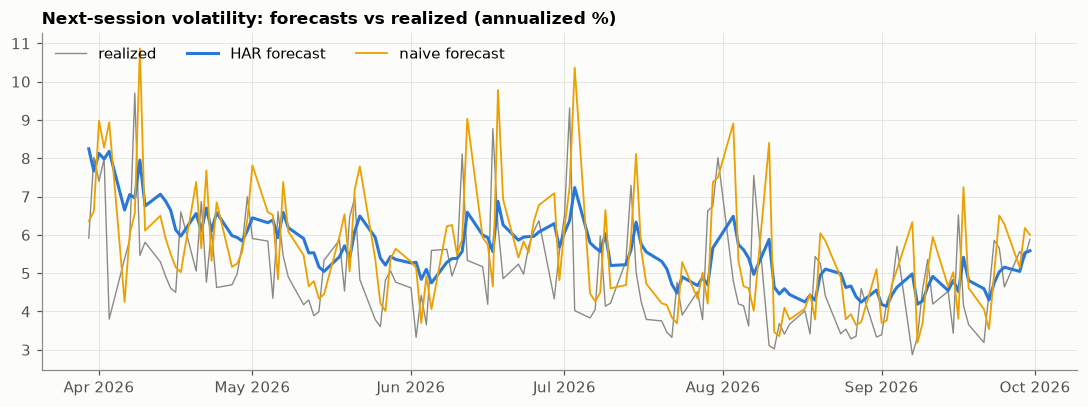

In [10]:
six_months_ago = variance["target_date"].max() - pd.DateOffset(months=6)
recent = variance.loc[variance["target_date"] >= six_months_ago]
fig, ax = plt.subplots(figsize=(10, 3.8))
actual = recent.loc[recent["model"] == "HAR"]
ax.plot(
    actual["target_date"],
    annualized_vol(actual["actual"]),
    color=ACTUAL,
    linewidth=0.9,
    label="realized",
)
for model in ["HAR", "naive"]:
    path = recent.loc[recent["model"] == model]
    ax.plot(
        path["target_date"],
        annualized_vol(path["predicted"]),
        color=COLORS[model],
        linewidth=2 if model == "HAR" else 1.2,
        label=f"{model} forecast",
    )
ax.set_title("Next-session volatility: forecasts vs realized (annualized %)")
ax.legend(loc="upper left", ncols=3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()

The naive forecast copies yesterday, so it chases every spike one day late.
HAR moves less: it blends today with the weekly and monthly levels, so a single
spike only partly carries over.

## 5. Results

**QLIKE.** Each forecast $h$ of the variance is scored against the realized
$\mathrm{RV}$ with

$$
L(\mathrm{RV}, h) = \frac{\mathrm{RV}}{h} - \log\frac{\mathrm{RV}}{h} - 1 \;\ge 0 .
$$

It is zero for a perfect forecast and depends only on the ratio, so a 20% miss
costs the same on a calm day as on a turbulent one. It punishes under-forecasting
more than over-forecasting: missing a 2× move costs 0.31, over-predicting by 2×
costs 0.19. And it ranks models correctly even though RV is only a noisy
measure of the true variance (Patton, 2011).

**Diebold–Mariano test.** For each benchmark, the test asks whether HAR's lower
average loss could be luck. The p-value is one-sided: a small value means HAR's
expected loss is lower. **HAR wins** is the share of sessions on which HAR had
the strictly lower loss.

In [11]:
table = experiment.results_table(comparison)
table.style.format(
    {
        "QLIKE": "{:.3f}",
        "HAR lower by": "{:.1%}",
        "DM p-value": "{:.1e}",
        "HAR wins": "{:.0%}",
    },
    na_rep="—",
)

,QLIKE,HAR lower by,DM p-value,HAR wins
model,,,,
HAR,0.152,0.0%,—,—
AR1,0.182,16.3%,2.4e-05,61%
EWMA,0.184,17.2%,8.1e-04,63%
naive,0.192,20.6%,2.2e-04,51%
historical_mean,0.326,53.2%,1.9e-11,76%


HAR has the lowest loss, 16–53% below each benchmark, and every DM p-value is
below 0.001. The win rates show *how* it wins: against the naive forecast it has
the lower loss on only about half of the sessions, yet a 21% lower mean loss.
HAR avoids the large misses that the naive forecast makes by copying every
spike into the next day.

Is the advantage steady or does it come from a few days? The cumulative sum of
the loss difference, benchmark minus HAR, rises when HAR does better.

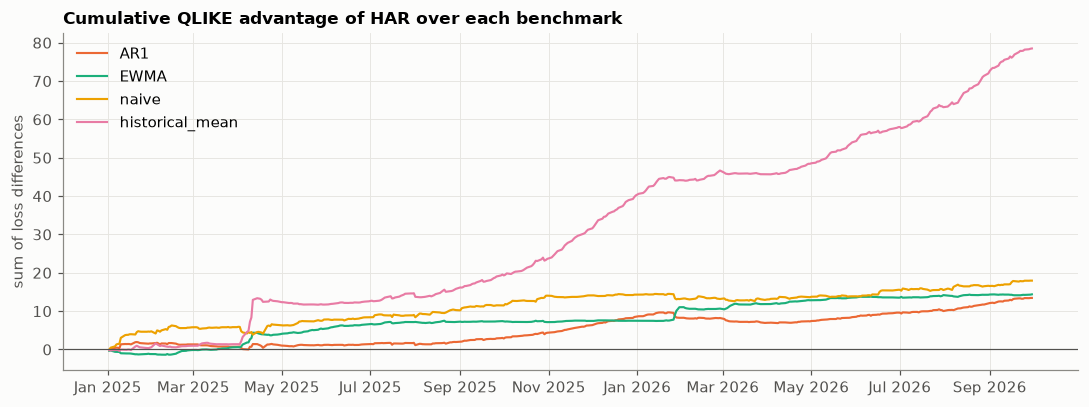

In [12]:
losses = comparison.losses.pivot(index="target_date", columns="model", values="loss")
fig, ax = plt.subplots(figsize=(10, 3.8))
for model in MODELS[1:]:
    advantage = (losses[model] - losses["HAR"]).cumsum()
    ax.plot(advantage.index, advantage, color=COLORS[model], label=model)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_title("Cumulative QLIKE advantage of HAR over each benchmark")
ax.set_ylabel("sum of loss differences")
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout()

Against the historical mean the gap grows steadily. Against the other
benchmarks it moves in steps on turbulent days, for example in April 2025, and
can shrink for a while in between. A few sessions matter a lot, which is why
the next section checks the result in several ways.

## 6. Robustness

### Does the verdict depend on the HAC lag?

The DM test has to account for the fact that neighbouring sessions are not
independent evidence: if HAR handles a turbulent week better, it wins that
week's sessions together. The test corrects for this with a Newey–West (HAC)
variance that looks a chosen number of sessions ahead. There is no single right
number, so we repeat the test for 0 to 5 lags.

In [13]:
sensitivity = hac_sensitivity(comparison.losses, "HAR")
sensitivity.pivot(index="baseline_model", columns="hac_lags", values="p_value").loc[
    MODELS[1:]
].style.format("{:.1e}")

hac_lags,0,1,2,3,4,5
baseline_model,,,,,,
AR1,1.2e-05,1.1e-05,1.5e-05,1.8e-05,2.1e-05,2.4e-05
EWMA,1.4e-06,4.0e-05,2.0e-04,4.1e-04,6.3e-04,8.1e-04
naive,2.0e-04,2.0e-04,1.8e-04,1.9e-04,2.1e-04,2.2e-04
historical_mean,3.6e-26,2.8e-19,1.4e-15,1.0e-13,2.3e-12,1.9e-11


Every p-value stays below 0.001 for every lag. For EWMA it grows with the lag,
as the correction for correlated sessions takes effect, but no conclusion
changes.

### Is the advantage spread over the sample?

Mean QLIKE per model and calendar month; the best model of each month is
highlighted.

In [14]:
monthly = (
    comparison.losses.assign(month=lambda t: t["target_date"].dt.strftime("%Y-%m"))
    .pivot_table(index="month", columns="model", values="loss", aggfunc="mean")
    .loc[:, MODELS]
)
best = monthly.idxmin(axis=1).value_counts().reindex(MODELS, fill_value=0)
print(f"months in which each model has the lowest mean loss ({len(monthly)} months):")
print(best.to_string())
monthly.style.highlight_min(axis=1, color="#cde2fb").format("{:.3f}")

months in which each model has the lowest mean loss (21 months):
HAR                11
AR1                 3
EWMA                4
naive               2
historical_mean     1


model,HAR,AR1,EWMA,naive,historical_mean
month,,,,,
2025-01,0.259,0.330,0.205,0.474,0.285
2025-02,0.214,0.203,0.267,0.267,0.234
2025-03,0.087,0.056,0.121,0.088,0.106
2025-04,0.313,0.329,0.469,0.334,0.813
2025-05,0.117,0.123,0.180,0.185,0.086
2025-06,0.096,0.104,0.151,0.124,0.136
2025-07,0.137,0.152,0.163,0.163,0.228
2025-08,0.284,0.295,0.286,0.345,0.339
2025-09,0.114,0.162,0.124,0.170,0.283


HAR has the lowest mean loss in 11 of the 21 months, and no other model leads in
more than four, so the result does not rest on a few unusual months.

### The worst days

HAR's five largest QLIKE losses. On each of these sessions realized volatility
was about twice HAR's forecast: sudden jumps, usually driven by news, that no
model built only on past volatility can anticipate. QLIKE punishes such
under-forecasts hardest.

In [15]:
har_losses = comparison.losses.query("model == 'HAR'")
worst = har_losses.nlargest(5, "loss")
share = worst["loss"].sum() / har_losses["loss"].sum()
print(f"5 sessions ({5 / len(har_losses):.1%} of the sample) make up {share:.0%} of HAR's loss")
pd.DataFrame(
    {
        "session": worst["target_date"].dt.date,
        "realized vol %": annualized_vol(worst["actual"]).round(1),
        "HAR forecast vol %": annualized_vol(worst["predicted"]).round(1),
        "QLIKE": worst["loss"].round(2),
    }
).reset_index(drop=True)

5 sessions (1.1% of the sample) make up 12% of HAR's loss


,session,realized vol %,HAR forecast vol %,QLIKE
0,2025-08-01,19.0,8.3,2.63
1,2026-03-23,16.8,8.2,1.74
2,2025-04-03,18.6,9.6,1.43
3,2026-01-27,13.3,6.9,1.41
4,2025-01-20,17.6,9.3,1.33


## 7. Conclusions

- **HAR forecasts best.** Its mean QLIKE is 16–53% lower than each benchmark's,
  and every difference is significant at the 0.1% level with a one-sided DM
  test, whatever the HAC lag.
- **It wins by avoiding large misses**, not by winning every day: against the
  naive forecast it has the lower loss on only about half of the sessions.
- **The reason is persistence at several horizons.** The weekly and monthly
  averages carry most of HAR's weight, matching the slowly decaying
  autocorrelation of log RV.
- The simpler benchmarks are close to each other: AR(1), EWMA and naive are
  within 6% in mean QLIKE.

**Limitations.**

- One currency pair and 21 months of evaluation; the next notebooks repeat the
  study on other assets.
- AR(1) is nested in HAR, so its DM test is conservative (Clark & West, 2007).
- The models are fitted by least squares on log RV but scored by QLIKE on
  variance, so none of them is tuned for the loss that ranks them.
- RV covers each session's own trading only, not the weekend gap, and uses a
  single 5-minute grid, a convention rather than an optimum.